# RAG Experiment: Dense Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** *D&D Basic Rules*, Version 1.0 (released November 2018)  
**Corpus:** the supplied `source.pdf` (180 PDF pages)  
**Task:** compare dense retrieval with cross-encoder re-ranking using the same source, embedding model, candidate pool, final context size, and grounded-answer prompt.

## Research question

Does re-ranking the top 10 dense-retrieval candidates with a cross-encoder improve the relevance of the top 3 passages supplied to a question-answering model, and what latency overhead does it add?

## Experimental protocol

| Component | Configuration |
|---|---|
| PDF extraction | `pypdf`, preserve 1-based PDF page number |
| Chunking | 1,000 characters, 180-character overlap, split within pages |
| Dense retriever | `sentence-transformers/all-MiniLM-L6-v2` + FAISS cosine similarity |
| Re-ranker | `cross-encoder/ms-marco-MiniLM-L-6-v2` |
| Candidate pool | Top 10 passages from dense retrieval |
| Final context | Top 3 passages for both pipelines |
| Evaluation | Page-grounded Recall@k, MRR@10, latency, rank movement, failure/abstention analysis |
| Answer generation | Optional Gemini API; requires `GEMINI_API_KEY` |

**Fair-comparison rule:** the re-ranker may reorder only the same top-10 candidates found by dense retrieval. It cannot recover a relevant passage that was absent from that candidate pool. Page labels in the evaluation set are manually specified targets, so retrieval metrics are a small, transparent, page-level proxy—not a substitute for a larger human-judged relevance set.

### Notebook sections
1. Environment and source-PDF validation
2. Text extraction and chunking
3. Embeddings and FAISS index
4. Dense retrieval and cross-encoder re-ranking
5. Page-grounded evaluation and latency profiling
6. Failure modes and out-of-document query
7. Optional grounded answer generation
8. Results, limitations, and exported artifacts

## 0. Environment setup

Run the notebook with Python 3.10–3.12 in a clean virtual/conda environment. Keep `source.pdf` in the same directory as this notebook, or place it in a `data/` subdirectory. The downloadable submission bundle includes the PDF and `requirements.txt`.

Install dependencies once from a terminal:

```bash
python -m pip install -r requirements.txt
```

For optional answer generation, create a `.env` file in the project directory containing:

```text
GEMINI_API_KEY=your_api_key_here
GEMINI_MODEL=gemini-3.8-flash
```

The retrieval and evaluation experiments run without an API key. Do not commit `.env` or expose an API key in a submitted notebook.

In [1]:
import os
import json
import time
import warnings
from pathlib import Path
from time import perf_counter
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
import torch
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    def load_dotenv(*args, **kwargs):
        return False

try:
    from google import genai
except ImportError:
    genai = None

from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 160)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python-ready imports loaded | device={DEVICE} | torch={torch.__version__}")

/home/arceus51/miniforge3/envs/experiments/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python-ready imports loaded | device=cpu | torch=2.14.1+cu130


## 1. Locate and validate the updated PDF

The notebook checks common project layouts. It deliberately validates that the selected file is the uploaded D&D rules document so an older `source.pdf` is not silently indexed by accident.

In [2]:
cwd = Path.cwd().resolve()
pdf_candidates = [
    cwd / "source.pdf",
    cwd / "data" / "source.pdf",
    cwd.parent / "source.pdf",
    cwd.parent / "data" / "source.pdf",
]
PDF_PATH = next((p for p in pdf_candidates if p.is_file()), None)

if PDF_PATH is None:
    checked = "\n".join(f" - {p}" for p in pdf_candidates)
    raise FileNotFoundError(
        "Could not locate source.pdf. Put it beside the notebook or under data/.\n"
        f"Locations checked:\n{checked}"
    )

reader = PdfReader(str(PDF_PATH))
if reader.is_encrypted:
    try:
        reader.decrypt("")
    except Exception as exc:
        raise RuntimeError("The supplied PDF is encrypted and could not be opened.") from exc

PDF_PAGE_COUNT = len(reader.pages)
PDF_METADATA = reader.metadata or {}

pages: list[dict[str, Any]] = []
for page_number, page in enumerate(reader.pages, start=1):
    page_text = (page.extract_text() or "").replace("\x00", "").strip()
    if page_text:
        pages.append({"page": page_number, "text": page_text})

all_first_page_text = pages[0]["text"] if pages else ""
if "D&D Basic Rules" not in all_first_page_text:
    warnings.warn(
        "The selected PDF does not appear to be the expected D&D Basic Rules document. "
        "Check PDF_PATH before continuing.",
        stacklevel=1,
    )

extracted_characters = sum(len(p["text"]) for p in pages)
source_summary = pd.DataFrame([{
    "PDF path": str(PDF_PATH),
    "PDF title metadata": str(PDF_METADATA.get("/Title", "Not set")),
    "PDF pages": PDF_PAGE_COUNT,
    "Pages with extractable text": len(pages),
    "Extracted characters": extracted_characters,
    "Text extraction coverage (%)": round(100 * len(pages) / max(PDF_PAGE_COUNT, 1), 2),
}])
display(source_summary)
print("First-page text preview:\n")
print(all_first_page_text[:900])

if not pages:
    raise ValueError("No extractable PDF text was found; OCR would be required for a scanned document.")

,PDF path,PDF title metadata,PDF pages,Pages with extractable text,Extracted characters,Text extraction coverage (%)
0,/home/arceus51/Projects/rag-baseline-reranking/data/source.pdf,Not set,180,180,779779,100.0


First-page text preview:

1
D&D Basic Rules, Version 1.0, Released November 2018
Credits 
Lead Designers: Jeremy Crawford, Mike Mearls, 
Christopher Perkins
Design Team: James Wyatt, Rodney Thompson, Robert J. 
Schwalb, Peter Lee, Steve Townshend, Bruce R. Cordell
Managing Editor: Jeremy Crawford
Editing Team: Chris Sims, Michele Carter, Scott Fitzgerald Gray, 
Kim Mohan
Graphic Designers: Bree Heiss, Emi Tanji
Interior Illustrator: Jaime Jones, Richard Whitters
Additional Contributors: Matt Sernett, Chris Dupuis, Tom 
LaPille, Chris Tulach, Miranda Horner, Jennifer Clarke Wilkes, 
Steve Winter, Chris Youngs, Ben Petrisor, Tom Olsen
Producer: Greg Bilsland
Project Management: Neil Shinkle, Kim Graham, John Hay
Brand and Marketing: Nathan Stewart, Liz Schuh, Chris Lindsay, 
Shelly Mazzanoble, Hilary Ross, Laura Tommervik, Kim 
Lundstrom, Trevor Kidd
DUNGEONS & DRAGONS, D&D , Wizards of the Coast, Forgotten Realms,


## 2. Chunk the PDF while retaining page citations

Chunking is performed **inside each PDF page**, so a chunk never crosses a page boundary. The 1-based page metadata is retained for citations and for the evaluation labels below. Repeated footers or table layouts can still affect retrieval; those are discussed as limitations.

In [3]:
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 180

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    add_start_index=True,
    separators=["\n\n", "\n", ". ", " ", ""],
)

documents: list[Document] = []
for page_record in pages:
    page_docs = splitter.create_documents(
        texts=[page_record["text"]],
        metadatas=[{"page": page_record["page"], "source": PDF_PATH.name}],
    )
    for doc in page_docs:
        doc.metadata["chunk_id"] = f"chunk_{len(documents):05d}"
        documents.append(doc)

if not documents:
    raise ValueError("Chunking produced no documents. Check PDF extraction and chunk size.")

chunk_df = pd.DataFrame([{
    "chunk_id": d.metadata["chunk_id"],
    "page": d.metadata["page"],
    "characters": len(d.page_content),
    "start_index": d.metadata.get("start_index"),
} for d in documents])

print(f"Pages with text: {len(pages)} | Chunks created: {len(documents)}")
display(chunk_df["characters"].describe().to_frame(name="Chunk characters").round(2))
display(chunk_df.head(8))
print("\nFirst chunk preview:\n", documents[0].page_content[:700])

Pages with text: 180 | Chunks created: 1008


,Chunk characters
count,1008.00
mean,902.47
std,184.44
min,159.00
25%,948.00
50%,970.00
75%,986.00
max,1000.00


,chunk_id,page,characters,start_index
0,chunk_00000,1,995,0
1,chunk_00001,1,999,835
2,chunk_00002,1,628,1669
3,chunk_00003,2,917,0
4,chunk_00004,2,968,825
5,chunk_00005,2,908,1655
6,chunk_00006,2,950,2384
7,chunk_00007,2,922,3163



First chunk preview:
 1
D&D Basic Rules, Version 1.0, Released November 2018
Credits 
Lead Designers: Jeremy Crawford, Mike Mearls, 
Christopher Perkins
Design Team: James Wyatt, Rodney Thompson, Robert J. 
Schwalb, Peter Lee, Steve Townshend, Bruce R. Cordell
Managing Editor: Jeremy Crawford
Editing Team: Chris Sims, Michele Carter, Scott Fitzgerald Gray, 
Kim Mohan
Graphic Designers: Bree Heiss, Emi Tanji
Interior Illustrator: Jaime Jones, Richard Whitters
Additional Contributors: Matt Sernett, Chris Dupuis, Tom 
LaPille, Chris Tulach, Miranda Horner, Jennifer Clarke Wilkes, 
Steve Winter, Chris Youngs, Ben Petrisor, Tom Olsen
Producer: Greg Bilsland
Project Management: Neil Shinkle, Kim Graham, John Hay
Brand 


## 3. Encode chunks and build the FAISS index

The embedding model encodes each chunk independently. Since vectors are L2-normalized, inner product is equivalent to cosine similarity. This builds an exact flat index, which is appropriate for a single-document experiment and avoids approximate-index tuning as a confound.

In [4]:
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

embedder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
chunk_texts = [d.page_content for d in documents]

embedding_start = perf_counter()
embeddings = embedder.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True,
).astype("float32")
embedding_seconds = perf_counter() - embedding_start

if embeddings.ndim != 2 or embeddings.shape[0] != len(documents):
    raise ValueError("Embedding matrix shape does not match the number of chunks.")

index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)

index_summary = pd.DataFrame([{
    "Embedding model": EMBEDDING_MODEL,
    "Embedding dimensions": embeddings.shape[1],
    "Indexed chunks": int(index.ntotal),
    "Embedding/index build time (s)": round(embedding_seconds, 3),
    "Device": DEVICE,
}])
display(index_summary)

Batches: 100%|██████████| 32/32 [00:14<00:00,  2.23it/s]


,Embedding model,Embedding dimensions,Indexed chunks,Embedding/index build time (s),Device
0,sentence-transformers/all-MiniLM-L6-v2,384,1008,14.329,cpu


### Persist the reusable index and chunk records

The generated `outputs/` directory contains index/chunk files and, after evaluation, CSV/JSON results. These are reproducibility artifacts; the notebook still rebuilds the index when run from top to bottom.

In [5]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

faiss.write_index(index, str(OUTPUT_DIR / "faiss.index"))
with (OUTPUT_DIR / "chunks.jsonl").open("w", encoding="utf-8") as f:
    for doc in documents:
        record = {
            "chunk_id": doc.metadata["chunk_id"],
            "page": int(doc.metadata["page"]),
            "source": doc.metadata["source"],
            "start_index": doc.metadata.get("start_index"),
            "text": doc.page_content,
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print(f"Saved FAISS index and chunk metadata to: {OUTPUT_DIR.resolve()}")

Saved FAISS index and chunk metadata to: /home/arceus51/Projects/rag-baseline-reranking/notebooks/outputs


## 4. Implement both retrieval pipelines

**Baseline:** embed the query, retrieve the top 10 chunks by cosine similarity, and pass the first 3 chunks to answer generation.  
**Re-ranked:** retrieve the same top 10 chunks, score each query–chunk pair jointly with a cross-encoder, then pass the highest-scoring 3 chunks to answer generation.

In [6]:
INITIAL_RETRIEVAL_K = 10
FINAL_CONTEXT_K = 3


def dense_retrieve(query: str, k: int = INITIAL_RETRIEVAL_K) -> list[dict[str, Any]]:
    """Retrieve the top-k chunks with normalized dense embeddings + FAISS."""
    if not isinstance(query, str) or not query.strip():
        raise ValueError("Query must be a non-empty string.")
    if k < 1:
        raise ValueError("k must be at least 1.")
    if index.ntotal == 0:
        return []

    query_vector = embedder.encode(
        [query.strip()],
        normalize_embeddings=True,
        convert_to_numpy=True,
    ).astype("float32")
    k_effective = min(k, index.ntotal)
    scores, indices = index.search(query_vector, k_effective)

    results = []
    for rank, (score, chunk_idx) in enumerate(zip(scores[0], indices[0]), start=1):
        if chunk_idx < 0:
            continue
        doc = documents[int(chunk_idx)]
        results.append({
            "rank": rank,
            "dense_rank": rank,
            "dense_score": float(score),
            "chunk_id": doc.metadata["chunk_id"],
            "page": int(doc.metadata["page"]),
            "source": doc.metadata["source"],
            "text": doc.page_content,
        })
    return results


reranker = CrossEncoder(RERANKER_MODEL, device=DEVICE)
print(f"Dense retriever ready: {EMBEDDING_MODEL}")
print(f"Cross-encoder ready: {RERANKER_MODEL} | device={DEVICE}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 5130.44it/s]


Dense retriever ready: sentence-transformers/all-MiniLM-L6-v2
Cross-encoder ready: cross-encoder/ms-marco-MiniLM-L-6-v2 | device=cpu


In [7]:
def rerank_results(query: str, candidates: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """Reorder only the supplied dense-retrieval candidates using a cross-encoder."""
    if not query.strip():
        raise ValueError("Query must be a non-empty string.")
    if not candidates:
        return []

    pairs = [(query, item["text"]) for item in candidates]
    scores = np.asarray(reranker.predict(
        pairs,
        batch_size=16,
        show_progress_bar=False,
        convert_to_numpy=True,
    )).reshape(-1)

    reranked = []
    for candidate, score in zip(candidates, scores):
        item = candidate.copy()
        item["dense_rank"] = candidate.get("dense_rank", candidate["rank"])
        item["reranker_score"] = float(score)
        reranked.append(item)

    reranked.sort(key=lambda item: item["reranker_score"], reverse=True)
    for rank, item in enumerate(reranked, start=1):
        item["rank"] = rank
        item["rerank_rank"] = rank
    return reranked


def ranking_frame(results: list[dict[str, Any]], pipeline: str) -> pd.DataFrame:
    """Readable view of a retrieval list."""
    return pd.DataFrame([{
        "Pipeline": pipeline,
        "Rank": item["rank"],
        "Chunk ID": item["chunk_id"],
        "PDF page": item["page"],
        "Dense score": round(item["dense_score"], 4),
        "Cross-encoder score": round(item["reranker_score"], 4) if "reranker_score" in item else np.nan,
        "Passage preview": item["text"].replace("\n", " ")[:220],
    } for item in results])

### Sanity-check one D&D question

This is an illustrative query, not the quantitative evaluation result. Review the actual retrieved passages and their PDF page numbers before interpreting a similarity score as evidence.

In [8]:
demo_query = "When a roll has advantage or disadvantage, how is the d20 result selected?"
_demo_t0 = perf_counter()
demo_baseline = dense_retrieve(demo_query, k=INITIAL_RETRIEVAL_K)
demo_dense_seconds = perf_counter() - _demo_t0
_demo_t0 = perf_counter()
demo_reranked = rerank_results(demo_query, demo_baseline)
demo_rerank_seconds = perf_counter() - _demo_t0

assert {x["chunk_id"] for x in demo_baseline} == {x["chunk_id"] for x in demo_reranked}, \
    "Fair-comparison check failed: candidate sets differ."

display(ranking_frame(demo_baseline[:FINAL_CONTEXT_K], "Dense baseline"))
display(ranking_frame(demo_reranked[:FINAL_CONTEXT_K], "Dense + cross-encoder"))
print(f"Dense retrieval: {demo_dense_seconds:.4f}s | Re-ranking: {demo_rerank_seconds:.4f}s")

,Pipeline,Rank,Chunk ID,PDF page,Dense score,Cross-encoder score,Passage preview
0,Dense baseline,1,chunk_00371,60,0.7447,NaN,"saving throw, or an attack roll. When that happens, you roll a second d20 when you make the roll. Use the higher of the two rolls if you have advantage, a..."
1,Dense baseline,2,chunk_00027,5,0.6924,NaN,55 Introduction D&D Basic Rules (Version 1.0). Not for resale. Permission granted to print and photocopy this document for personal use only. Advantage and ...
2,Dense baseline,3,chunk_00372,60,0.6218,NaN,"advantage or vice versa. In such a situation, you have nei - ther advantage nor disadvantage. When you have advantage or disadvantage and some - thing in t..."


,Pipeline,Rank,Chunk ID,PDF page,Dense score,Cross-encoder score,Passage preview
0,Dense + cross-encoder,1,chunk_00027,5,0.6924,6.4066,55 Introduction D&D Basic Rules (Version 1.0). Not for resale. Permission granted to print and photocopy this document for personal use only. Advantage and ...
1,Dense + cross-encoder,2,chunk_00371,60,0.7447,6.3799,"saving throw, or an attack roll. When that happens, you roll a second d20 when you make the roll. Use the higher of the two rolls if you have advantage, a..."
2,Dense + cross-encoder,3,chunk_00372,60,0.6218,6.1250,"advantage or vice versa. In such a situation, you have nei - ther advantage nor disadvantage. When you have advantage or disadvantage and some - thing in t..."


Dense retrieval: 0.0084s | Re-ranking: 0.1509s


## 5. Evaluation set and ground-truth page labels

The questions below are written against the supplied *D&D Basic Rules* PDF. `gold_pages` is the manually annotated list of PDF pages expected to contain directly useful evidence. A question can have more than one supporting page. The deliberately out-of-document question has an empty `gold_pages` list and is excluded from retrieval relevance averages; it is used for failure/abstention analysis instead.

Page-level relevance is a practical starting label for this single-document assignment. For a stronger research evaluation, manually label relevant **chunks** and increase the number/diversity of questions.

In [9]:
evaluation_queries = [
    {
        "query_id": "Q1", "type": "Direct retrieval",
        "question": "According to the basic pattern of play, what three steps repeat during an adventure?",
        "gold_pages": [4], "answerable": True,
    },
    {
        "query_id": "Q2", "type": "Rule condition",
        "question": "When a roll has advantage or disadvantage, how is the d20 result selected?",
        "gold_pages": [5], "answerable": True,
    },
    {
        "query_id": "Q3", "type": "Exception handling",
        "question": "If a specific rule contradicts a general game rule, which rule takes precedence?",
        "gold_pages": [5], "answerable": True,
    },
    {
        "query_id": "Q4", "type": "Numerical/detail retrieval",
        "question": "In the Bruenor example, with Strength 17 (+3) and proficiency bonus +2, what are the battleaxe attack bonus and damage on a hit?",
        "gold_pages": [11], "answerable": True,
    },
    {
        "query_id": "Q5", "type": "Comparison",
        "question": "How do the ability modifiers for melee and ranged weapon attacks differ, and what exception is described for finesse weapons?",
        "gold_pages": [11], "answerable": True,
    },
    {
        "query_id": "Q6", "type": "Cross-section / procedural detail",
        "question": "When may a character spend Hit Dice to regain hit points, and what is the purpose of Hit Dice?",
        "gold_pages": [8, 70], "answerable": True,
    },
    {
        "query_id": "Q7", "type": "Out-of-document / abstention",
        "question": "What Weapon Mastery property does a glaive have under the 2024 Player's Handbook?",
        "gold_pages": [], "answerable": False,
    },
]

display(pd.DataFrame([{
    "ID": q["query_id"], "Question type": q["type"],
    "Question": q["question"], "Gold PDF pages": q["gold_pages"] or "Not in source",
    "Answerable from this PDF?": q["answerable"],
} for q in evaluation_queries]))

,ID,Question type,Question,Gold PDF pages,Answerable from this PDF?
0,Q1,Direct retrieval,"According to the basic pattern of play, what three steps repeat during an adventure?",[4],True
1,Q2,Rule condition,"When a roll has advantage or disadvantage, how is the d20 result selected?",[5],True
2,Q3,Exception handling,"If a specific rule contradicts a general game rule, which rule takes precedence?",[5],True
3,Q4,Numerical/detail retrieval,"In the Bruenor example, with Strength 17 (+3) and proficiency bonus +2, what are the battleaxe attack bonus and damage on a hit?",[11],True
4,Q5,Comparison,"How do the ability modifiers for melee and ranged weapon attacks differ, and what exception is described for finesse weapons?",[11],True
5,Q6,Cross-section / procedural detail,"When may a character spend Hit Dice to regain hit points, and what is the purpose of Hit Dice?","[8, 70]",True
6,Q7,Out-of-document / abstention,What Weapon Mastery property does a glaive have under the 2024 Player's Handbook?,Not in source,False


### Evaluation metrics

- **Recall@k (page-level):** fraction of annotated supporting pages represented in the top *k* chunks, counting each relevant page once.
- **MRR@10:** reciprocal rank of the first retrieved chunk from an annotated supporting page, averaged across answerable questions.
- **Hit@3:** whether at least one annotated supporting page appears in the final three chunks.
- **Latency:** query embedding + FAISS retrieval time and cross-encoder re-ranking time, measured separately.

Because re-ranking uses the same dense top-10 candidates, its Recall@10 should remain unchanged. A difference in top-3 metrics reflects ordering, not expanded candidate recall.

In [10]:
K_VALUES = (1, 3, 5, 10)


def calculate_page_metrics(results: list[dict[str, Any]], gold_pages: list[int]) -> dict[str, float]:
    """Compute page-level ranking metrics using manually annotated PDF pages."""
    if not gold_pages:
        return {**{f"Recall@{k}": np.nan for k in K_VALUES}, "MRR@10": np.nan, "Hit@3": np.nan}

    gold = set(int(p) for p in gold_pages)
    metrics: dict[str, float] = {}
    for k in K_VALUES:
        observed_pages = {int(r["page"]) for r in results[:k]}
        metrics[f"Recall@{k}"] = len(gold.intersection(observed_pages)) / len(gold)

    first_relevant_rank = next(
        (rank for rank, result in enumerate(results[:10], start=1) if int(result["page"]) in gold),
        None,
    )
    metrics["MRR@10"] = 1.0 / first_relevant_rank if first_relevant_rank is not None else 0.0
    metrics["Hit@3"] = float(any(int(r["page"]) in gold for r in results[:3]))
    return metrics


metric_rows = []
latency_rows = []
rank_records = []
query_results: dict[str, dict[str, Any]] = {}

for q in evaluation_queries:
    if not q["answerable"]:
        continue

    start = perf_counter()
    baseline = dense_retrieve(q["question"], k=INITIAL_RETRIEVAL_K)
    dense_seconds = perf_counter() - start

    start = perf_counter()
    reranked = rerank_results(q["question"], baseline)
    rerank_seconds = perf_counter() - start

    # The candidate pool must be identical; cross-encoder scoring changes order only.
    assert {x["chunk_id"] for x in baseline} == {x["chunk_id"] for x in reranked}
    assert len(baseline) == len(reranked) == min(INITIAL_RETRIEVAL_K, index.ntotal)

    query_results[q["query_id"]] = {
        "question": q["question"],
        "gold_pages": q["gold_pages"],
        "baseline": baseline,
        "reranked": reranked,
        "dense_seconds": dense_seconds,
        "rerank_seconds": rerank_seconds,
    }

    for pipeline_name, ranked_list in [
        ("Dense baseline", baseline),
        ("Dense + cross-encoder", reranked),
    ]:
        metric_rows.append({
            "Query ID": q["query_id"], "Question type": q["type"],
            "Pipeline": pipeline_name,
            **calculate_page_metrics(ranked_list, q["gold_pages"]),
        })

    latency_rows.append({"Query ID": q["query_id"], "Operation": "Dense query + FAISS retrieval", "Seconds": dense_seconds})
    latency_rows.append({"Query ID": q["query_id"], "Operation": "Cross-encoder re-ranking of top 10", "Seconds": rerank_seconds})

    dense_ranks = {x["chunk_id"]: x["rank"] for x in baseline}
    rerank_ranks = {x["chunk_id"]: x["rank"] for x in reranked}
    for item in baseline:
        rank_records.append({
            "query_id": q["query_id"], "question": q["question"],
            "chunk_id": item["chunk_id"], "page": item["page"],
            "dense_rank": dense_ranks[item["chunk_id"]],
            "rerank_rank": rerank_ranks[item["chunk_id"]],
            "rank_improvement": dense_ranks[item["chunk_id"]] - rerank_ranks[item["chunk_id"]],
            "dense_score": item["dense_score"],
            "reranker_score": next(x["reranker_score"] for x in reranked if x["chunk_id"] == item["chunk_id"]),
        })

metrics_df = pd.DataFrame(metric_rows)
latency_df = pd.DataFrame(latency_rows)
rankings_df = pd.DataFrame(rank_records)
print(f"Evaluated {len(query_results)} answerable questions; excluded the out-of-document question from relevance averages.")
display(metrics_df)

Evaluated 6 answerable questions; excluded the out-of-document question from relevance averages.


,Query ID,Question type,Pipeline,Recall@1,Recall@3,Recall@5,Recall@10,MRR@10,Hit@3
0,Q1,Direct retrieval,Dense baseline,0.0,1.0,1.0,1.0,0.333333,1.0
1,Q1,Direct retrieval,Dense + cross-encoder,1.0,1.0,1.0,1.0,1.000000,1.0
2,Q2,Rule condition,Dense baseline,0.0,1.0,1.0,1.0,0.500000,1.0
3,Q2,Rule condition,Dense + cross-encoder,1.0,1.0,1.0,1.0,1.000000,1.0
4,Q3,Exception handling,Dense baseline,1.0,1.0,1.0,1.0,1.000000,1.0
5,Q3,Exception handling,Dense + cross-encoder,1.0,1.0,1.0,1.0,1.000000,1.0
6,Q4,Numerical/detail retrieval,Dense baseline,1.0,1.0,1.0,1.0,1.000000,1.0
7,Q4,Numerical/detail retrieval,Dense + cross-encoder,1.0,1.0,1.0,1.0,1.000000,1.0
8,Q5,Comparison,Dense baseline,0.0,0.0,0.0,1.0,0.166667,0.0
9,Q5,Comparison,Dense + cross-encoder,0.0,1.0,1.0,1.0,0.500000,1.0


## 6. Aggregate results and visualize the comparison

The next cell aggregates measured outcomes; it does not assume that re-ranking wins. Interpret gains alongside re-ranking latency and the limits of a small, page-labeled test set.

,Recall@1,Recall@3,Recall@5,Recall@10,MRR@10,Hit@3
Pipeline,,,,,,
Dense + cross-encoder,0.7500,0.9167,1.00,1.0,0.9167,1.0000
Dense baseline,0.4167,0.7500,0.75,1.0,0.6667,0.8333


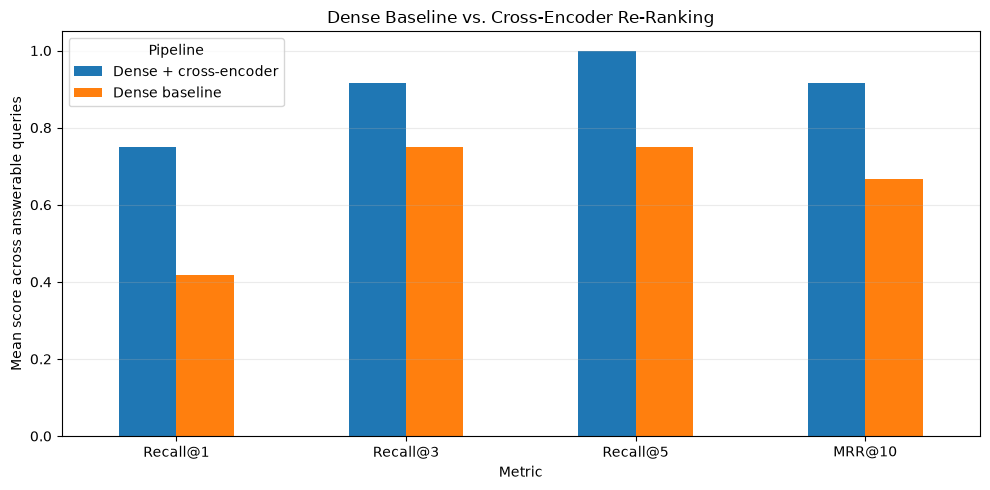

,mean,median,std
Operation,,,
Cross-encoder re-ranking of top 10,0.1575,0.1408,0.0328
Dense query + FAISS retrieval,0.0071,0.0075,0.0014


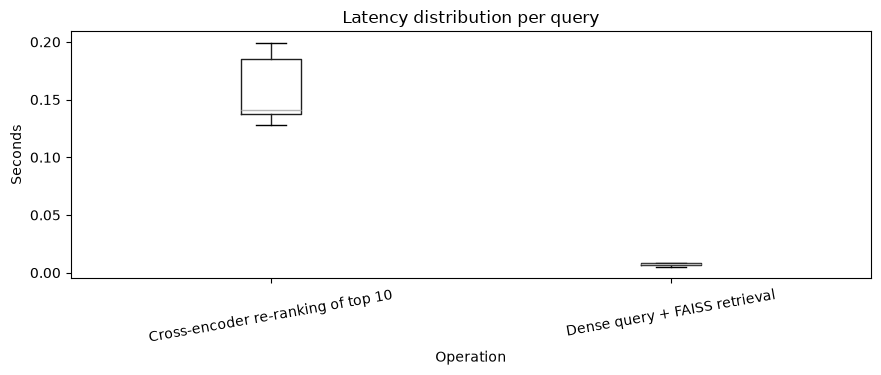

In [11]:
metric_columns = [f"Recall@{k}" for k in K_VALUES] + ["MRR@10", "Hit@3"]
aggregate_metrics = metrics_df.groupby("Pipeline")[metric_columns].mean().round(4)
display(aggregate_metrics)

metric_plot = aggregate_metrics[["Recall@1", "Recall@3", "Recall@5", "MRR@10"]].T
ax = metric_plot.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Dense Baseline vs. Cross-Encoder Re-Ranking")
ax.set_ylabel("Mean score across answerable queries")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1.05)
ax.legend(title="Pipeline")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

latency_summary = latency_df.groupby("Operation")["Seconds"].agg(["mean", "median", "std"]).round(4)
display(latency_summary)
ax = latency_df.boxplot(column="Seconds", by="Operation", figsize=(9, 4), grid=False, rot=10)
ax.set_title("Latency distribution per query")
ax.set_ylabel("Seconds")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 7. Inspect rank movement and the actual final contexts

A cross-encoder score is a relevance score for its query–passage pair, not a probability that the passage is correct. The passages and original PDF page numbers remain the evidence that should be checked.

In [12]:
PRIMARY_QUERY_ID = "Q4"  # detailed numerical example from the source PDF
primary = query_results[PRIMARY_QUERY_ID]
dense_rank_by_id = {x["chunk_id"]: x["rank"] for x in primary["baseline"]}

rank_comparison = pd.DataFrame([{
    "Chunk ID": item["chunk_id"],
    "PDF page": item["page"],
    "Dense rank": item["dense_rank"],
    "Re-ranked position": item["rerank_rank"],
    "Rank improvement (+ is better)": item["dense_rank"] - item["rerank_rank"],
    "Dense cosine score": round(item["dense_score"], 4),
    "Cross-encoder score": round(item["reranker_score"], 4),
} for item in rank_records if item["query_id"] == PRIMARY_QUERY_ID]).sort_values("Re-ranked position")

display(Markdown(f"**Question:** {primary['question']}"))
display(rank_comparison)

def show_contexts(label: str, results: list[dict[str, Any]], score_key: str):
    print("\n" + "=" * 90 + f"\n{label} — FINAL TOP {FINAL_CONTEXT_K}\n" + "=" * 90)
    for item in results[:FINAL_CONTEXT_K]:
        score = item.get(score_key, float("nan"))
        print(f"\nRank {item['rank']} | {item['chunk_id']} | PDF page {item['page']} | score={score:.4f}")
        print(item["text"][:700])

show_contexts("DENSE BASELINE", primary["baseline"], "dense_score")
show_contexts("DENSE + CROSS-ENCODER", primary["reranked"], "reranker_score")

**Question:** In the Bruenor example, with Strength 17 (+3) and proficiency bonus +2, what are the battleaxe attack bonus and damage on a hit?

,Chunk ID,PDF page,Dense rank,Re-ranked position,Rank improvement (+ is better),Dense cosine score,Cross-encoder score
0,chunk_00066,11,1,1,0,0.6291,6.7713
1,chunk_00065,11,2,2,0,0.5451,2.9816
2,chunk_00056,9,3,3,0,0.5066,2.8671
3,chunk_00053,9,4,4,0,0.4488,0.3987
8,chunk_00054,9,9,5,4,0.3933,-0.2992
6,chunk_00732,117,7,6,1,0.4077,-6.5069
7,chunk_00750,121,8,7,1,0.4031,-6.6967
4,chunk_00490,77,5,8,-3,0.4336,-6.9385
9,chunk_00835,141,10,9,1,0.3895,-7.7057
5,chunk_00880,152,6,10,-4,0.4078,-8.7297



DENSE BASELINE — FINAL TOP 3

Rank 1 | chunk_00066 | PDF page 11 | score=0.6291
For Bruenor’s weapons, Bob chooses a battleaxe 
and two handaxes. His battleaxe is a melee weapon, so 
Bruenor uses his Strength modifier for his attacks and 
damage. His attack bonus is his Strength modifier (+3) 
plus his proficiency bonus (+2), for a total of +5. The bat-
tleaxe deals 1d8 slashing damage, and Bruenor adds his 
Strength modifier to the damage when he hits, for a total 
of 1d8 + 3 slashing damage. When throwing a handaxe, 
Bruenor has the same attack bonus (handaxes, as thrown 
weapons, use Strength for attacks and damage), and the 
weapon deals 1d6 + 3 slashing damage when it hits.
6. Come Together
Most D&D characters don’t work alone. Each charac -
ter plays a role within

Rank 2 | chunk_00065 | PDF page 11 | score=0.5451
When you make an attack with a weapon, you roll 
a d20 and add your proficiency bonus (but only if you 
are proficient with the weapon) and the appropriate 
ability mo

## 8. Failure-mode analysis

The notebook checks three common RAG failure modes:

1. **Out-of-document question:** the similarity search will still return passages, even when the requested rule is not in this 2018 document.
2. **Exception/condition retrieval:** a system may retrieve a broad rule but miss the exception that changes the outcome.
3. **Multi-detail question:** a response can sound plausible while missing a numeric detail, condition, or source citation.

The first case is tested directly below. The other cases are represented by Q3–Q6 in the evaluation set; inspect their top-three passages and rank metrics instead of assuming retrieval succeeded.

In [13]:
out_of_scope = next(q for q in evaluation_queries if q["query_id"] == "Q7")
start = perf_counter()
q7_baseline = dense_retrieve(out_of_scope["question"], k=INITIAL_RETRIEVAL_K)
q7_dense_seconds = perf_counter() - start
start = perf_counter()
q7_reranked = rerank_results(out_of_scope["question"], q7_baseline)
q7_rerank_seconds = perf_counter() - start

print("OUT-OF-DOCUMENT QUERY:", out_of_scope["question"])
print("Expected answerability from this source:", out_of_scope["answerable"])
print("Note: a ranked result is not proof that the PDF contains an answer.\n")

display(ranking_frame(q7_baseline[:FINAL_CONTEXT_K], "Dense baseline — nearest matches"))
display(ranking_frame(q7_reranked[:FINAL_CONTEXT_K], "Re-ranked — nearest matches"))
print(f"Dense retrieval: {q7_dense_seconds:.4f}s | Re-ranking: {q7_rerank_seconds:.4f}s")

failure_summary = pd.DataFrame([
    {"Failure mode": "Out-of-document request", "Question ID": "Q7", "What to inspect": "Nearest chunks may be topically related but cannot establish 2024 Weapon Mastery rules."},
    {"Failure mode": "Exception/condition may be missed", "Question ID": "Q3", "What to inspect": "Does the top-three context include the specific-beats-general rule?"},
    {"Failure mode": "Multi-detail answer may be incomplete", "Question ID": "Q4", "What to inspect": "Are Strength modifier, proficiency bonus, attack bonus, and damage expression all supported?"},
])
display(failure_summary)

OUT-OF-DOCUMENT QUERY: What Weapon Mastery property does a glaive have under the 2024 Player's Handbook?
Expected answerability from this source: False
Note: a ranked result is not proof that the PDF contains an answer.



,Pipeline,Rank,Chunk ID,PDF page,Dense score,Cross-encoder score,Passage preview
0,Dense baseline — nearest matches,1,chunk_00065,11,0.4566,NaN,"When you make an attack with a weapon, you roll a d20 and add your proficiency bonus (but only if you are proficient with the weapon) and the appropriate ..."
1,Dense baseline — nearest matches,2,chunk_00929,163,0.3792,NaN,163163 Chapter 12: Monsters D&D Basic Rules (Version 1.0). Not for resale. Permission granted to print and photocopy this document for personal use only. Co...
2,Dense baseline — nearest matches,3,chunk_00313,50,0.3774,NaN,5050 Chapter 5: Equipment D&D Basic Rules (Version 1.0). Not for resale. Permission granted to print and photocopy this document for personal use only. Adve...


,Pipeline,Rank,Chunk ID,PDF page,Dense score,Cross-encoder score,Passage preview
0,Re-ranked — nearest matches,1,chunk_00065,11,0.4566,-8.0344,"When you make an attack with a weapon, you roll a d20 and add your proficiency bonus (but only if you are proficient with the weapon) and the appropriate ..."
1,Re-ranked — nearest matches,2,chunk_00006,2,0.3338,-8.1682,Weapons ..................................................................................47 Adventuring Gear ................................................
2,Re-ranked — nearest matches,3,chunk_00302,48,0.3354,-9.6356,"Dagger 2 gp 1d4 piercing 1 lb. Finesse, light, thrown (range 20/60) Greatclub 2 sp 1d8 bludgeoning 10 lb. Two-handed Handaxe 5 gp 1d6 slashing 2 lb. Light, ..."


Dense retrieval: 0.0077s | Re-ranking: 0.3670s


,Failure mode,Question ID,What to inspect
0,Out-of-document request,Q7,Nearest chunks may be topically related but cannot establish 2024 Weapon Mastery rules.
1,Exception/condition may be missed,Q3,Does the top-three context include the specific-beats-general rule?
2,Multi-detail answer may be incomplete,Q4,"Are Strength modifier, proficiency bonus, attack bonus, and damage expression all supported?"


## 9. Optional grounded answer generation (Gemini)


In [17]:
load_dotenv()
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
GENERATION_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.8-flash")
GENERATION_AVAILABLE = bool(GEMINI_API_KEY) and genai is not None

if GENERATION_AVAILABLE:
    genai_client = genai.Client(api_key=GEMINI_API_KEY)
    print(f"Optional generation enabled | model={GENERATION_MODEL}")
else:
    genai_client = None
    print("Optional generation skipped: set GEMINI_API_KEY and install google-genai to enable it.")


def generate_grounded_answer(query: str, selected_chunks: list[dict[str, Any]]) -> dict[str, Any]:
    """Generate an answer grounded only in the provided retrieved passages."""
    if genai_client is None:
        raise RuntimeError("Generation is not configured. Set GEMINI_API_KEY and install google-genai.")
    if not selected_chunks:
        raise ValueError("At least one retrieved chunk is required.")

    context = "\n\n".join(
        f"[{chunk['chunk_id']}, PDF page {chunk['page']}]\n{chunk['text']}"
        for chunk in selected_chunks
    )
    prompt = f"""You are a careful question-answering assistant for the supplied D&D Basic Rules, Version 1.0 (2018).
Use only the evidence in the excerpts below. Do not fill gaps with outside D&D knowledge or later-edition rules.
Cite every substantive claim using the exact chunk ID and PDF page, for example [chunk_00031, PDF page 17].
If the excerpts do not establish an answer, say that the supplied excerpts do not contain enough evidence.
Be precise about numerical values, conditions, exceptions, and edition/version boundaries.

EXCERPTS:
{context}

QUESTION:
{query}

GROUNDED ANSWER:"""

    started = perf_counter()
    response = genai_client.models.generate_content(model=GENERATION_MODEL, contents=prompt)
    elapsed = perf_counter() - started
    answer_text = (getattr(response, "text", None) or "").strip()
    if not answer_text:
        raise RuntimeError("The generation API returned an empty text response.")
    return {"answer": answer_text, "generation_seconds": elapsed, "model": GENERATION_MODEL}

Optional generation enabled | model=gemini-3.8-flash


## 10. Results interpretation

The following cell generates a compact summary from the measured metrics. Use it as a starting point for the report, then add a short qualitative discussion referencing the actual passages and any generation output. Do **not** claim that re-ranking is better unless the observed metrics support that claim.

In [22]:
def safe_metric(pipeline: str, metric: str) -> float:
    try:
        return float(aggregate_metrics.loc[pipeline, metric])
    except (KeyError, TypeError, ValueError):
        return float("nan")

baseline_r3 = safe_metric("Dense baseline", "Recall@3")
reranked_r3 = safe_metric("Dense + cross-encoder", "Recall@3")
baseline_mrr = safe_metric("Dense baseline", "MRR@10")
reranked_mrr = safe_metric("Dense + cross-encoder", "MRR@10")
latency_means = latency_df.groupby("Operation")["Seconds"].mean().to_dict()
dense_mean = float(latency_means.get("Dense query + FAISS retrieval", np.nan))
rerank_mean = float(latency_means.get("Cross-encoder re-ranking of top 10", np.nan))

if np.isfinite(reranked_r3) and np.isfinite(baseline_r3):
    if reranked_r3 > baseline_r3:
        retrieval_interpretation = f"Re-ranking improved mean Recall@3 by {reranked_r3 - baseline_r3:.3f} on this annotated question set."
    elif reranked_r3 < baseline_r3:
        retrieval_interpretation = f"Re-ranking reduced mean Recall@3 by {baseline_r3 - reranked_r3:.3f} on this annotated question set."
    else:
        retrieval_interpretation = "Mean Recall@3 was unchanged after re-ranking on this annotated question set."
else:
    retrieval_interpretation = "Recall@3 could not be computed; inspect the evaluation labels and outputs."

summary_md = f"""### Observed results

- Mean **Recall@3** — dense baseline: **{baseline_r3:.3f}**; dense + cross-encoder: **{reranked_r3:.3f}**.
- Mean **MRR@10** — dense baseline: **{baseline_mrr:.3f}**; dense + cross-encoder: **{reranked_mrr:.3f}**.
- Mean dense query + FAISS retrieval latency: **{dense_mean:.4f} s/query**.
- Mean cross-encoder re-ranking latency for the top 10: **{rerank_mean:.4f} s/query**.

**Interpretation:** {retrieval_interpretation}

These values apply only to the questions and page labels defined in this notebook. The test set is small, page-level relevance is approximate, and re-ranking latency excludes LLM answer generation. Inspect Q3–Q6 and the actual top-three passages before drawing a broader conclusion."""
display(Markdown(summary_md))

### Observed results

- Mean **Recall@3** — dense baseline: **0.750**; dense + cross-encoder: **0.917**.
- Mean **MRR@10** — dense baseline: **0.667**; dense + cross-encoder: **0.917**.
- Mean dense query + FAISS retrieval latency: **0.0071 s/query**.
- Mean cross-encoder re-ranking latency for the top 10: **0.1575 s/query**.

**Interpretation:** Re-ranking improved mean Recall@3 by 0.167 on this annotated question set.

These values apply only to the questions and page labels defined in this notebook. The test set is small, page-level relevance is approximate, and re-ranking latency excludes LLM answer generation. Inspect Q3–Q6 and the actual top-three passages before drawing a broader conclusion.

## 11. Export experiment artifacts

The output files make the experiment auditable and simplify inclusion of tables in a report. Raw passage texts are in `chunks.jsonl`; retrieval rankings and measured metrics are in CSV files.

In [23]:
metrics_df.to_csv(OUTPUT_DIR / "query_level_metrics.csv", index=False)
aggregate_metrics.to_csv(OUTPUT_DIR / "aggregate_metrics.csv")
latency_df.to_csv(OUTPUT_DIR / "latency_profile.csv", index=False)
rankings_df.to_csv(OUTPUT_DIR / "rank_movements.csv", index=False)
chunk_df.to_csv(OUTPUT_DIR / "chunk_inventory.csv", index=False)

with (OUTPUT_DIR / "evaluation_questions.json").open("w", encoding="utf-8") as f:
    json.dump(evaluation_queries, f, ensure_ascii=False, indent=2)

with (OUTPUT_DIR / "top10_rankings.jsonl").open("w", encoding="utf-8") as f:
    for query_id, record in query_results.items():
        for pipeline_name in ("baseline", "reranked"):
            for item in record[pipeline_name]:
                saved = {
                    "query_id": query_id,
                    "question": record["question"],
                    "pipeline": pipeline_name,
                    "rank": item["rank"],
                    "chunk_id": item["chunk_id"],
                    "page": item["page"],
                    "dense_score": item.get("dense_score"),
                    "reranker_score": item.get("reranker_score"),
                    "text": item["text"],
                }
                f.write(json.dumps(saved, ensure_ascii=False) + "\n")

if answer_records:
    pd.DataFrame(answer_records).to_csv(OUTPUT_DIR / "generated_answer_comparison.csv", index=False)

run_summary = {
    "source_pdf": PDF_PATH.name,
    "pdf_pages": PDF_PAGE_COUNT,
    "pages_with_text": len(pages),
    "extracted_characters": extracted_characters,
    "chunk_count": len(documents),
    "chunk_size": CHUNK_SIZE,
    "chunk_overlap": CHUNK_OVERLAP,
    "embedding_model": EMBEDDING_MODEL,
    "reranker_model": RERANKER_MODEL,
    "initial_retrieval_k": INITIAL_RETRIEVAL_K,
    "final_context_k": FINAL_CONTEXT_K,
    "device": DEVICE,
    "embedding_and_index_build_seconds": embedding_seconds,
    "answer_generation_enabled": GENERATION_AVAILABLE,
    "generation_model": GENERATION_MODEL if GENERATION_AVAILABLE else None,
    "mean_metrics": aggregate_metrics.reset_index().to_dict(orient="records"),
    "mean_dense_retrieval_seconds": dense_mean,
    "mean_reranking_seconds": rerank_mean,
}
with (OUTPUT_DIR / "run_summary.json").open("w", encoding="utf-8") as f:
    json.dump(run_summary, f, ensure_ascii=False, indent=2)

print("Exported experiment artifacts:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f" - {path.name}: {path.stat().st_size:,} bytes")

Exported experiment artifacts:
 - aggregate_metrics.csv: 162 bytes
 - chunk_inventory.csv: 23,838 bytes
 - chunks.jsonl: 1,033,444 bytes
 - evaluation_questions.json: 1,688 bytes
 - faiss.index: 1,548,333 bytes
 - latency_profile.csv: 694 bytes
 - query_level_metrics.csv: 905 bytes
 - rank_movements.csv: 9,887 bytes
 - run_summary.json: 1,033 bytes
 - top10_rankings.jsonl: 150,492 bytes


## 12. Conclusion and limitations

Complete the short conclusion after inspecting your run's tables and passages. The generated summary above provides measured metrics but does not replace an evidence-based interpretation.

### Recommended submission discussion

1. State whether re-ranking changed Recall@3 and MRR@10 on this query set, citing the measured values.
2. Explain the latency trade-off between dense retrieval and cross-encoder scoring.
3. Give one concrete success or rank movement from Q3–Q6 and identify its source page.
4. Discuss Q7: nearest-neighbor retrieval always returns candidates, so a RAG system needs an abstention rule based on evidence sufficiency—not similarity alone.
5. Acknowledge limitations: only six answerable queries, manually assigned page labels rather than exhaustive chunk labels, one document/version, model/domain mismatch risk, extraction errors around tables/columns, and optional LLM output variability.

### Technical limitations

- The metrics depend on the correctness and completeness of `gold_pages`; inspect these labels against the PDF before final submission.
- Since the re-ranker only reorders dense top-10 candidates, retrieval recall is bounded by the candidate pool.
- Cross-encoder scores and cosine similarity scores are not directly comparable and neither is a calibrated probability.
- An LLM answer should be judged for correctness and citation support separately from retrieval metrics.
- The PDF includes tables, stat blocks, and visually structured content; plain-text extraction may not preserve every layout relationship.